In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model, plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

from numpy.lib.stride_tricks import sliding_window_view

I0000 00:00:1794407764.580097 3758737 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794407764.612790 3758737 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794407765.316591 3758737 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h1> Import Data

Text(0.5, 0.98, 'All Data')

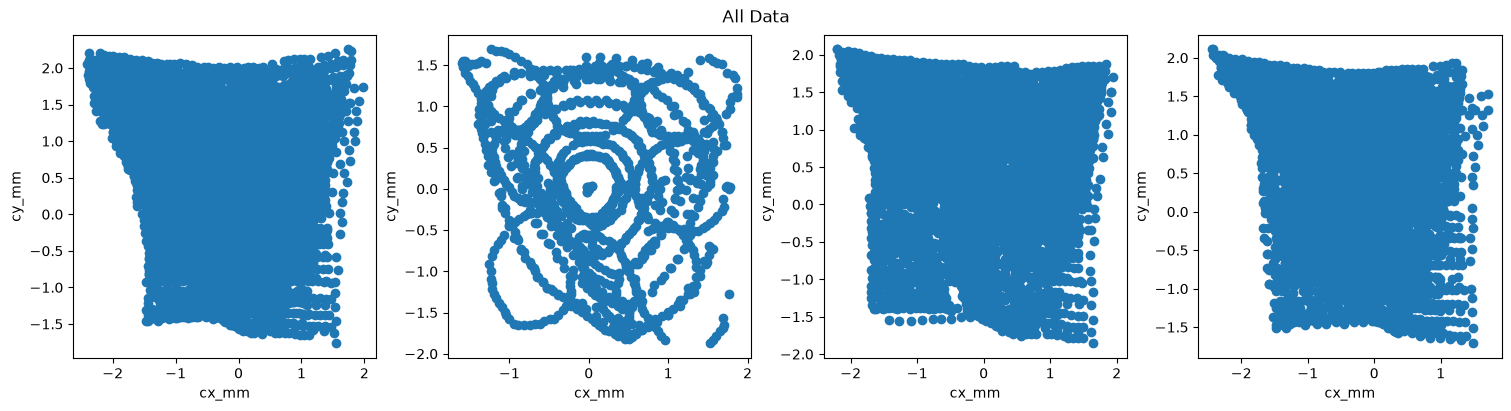

In [3]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64

#remove nans
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()

data_list = [ data_1, data_2, data_0, data_3] #data_0,

fig, axs = plt.subplots(1, 4, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2>Concatenate

In [4]:
all_data = pd.concat(data_list, ignore_index=True)

In [5]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

<h3>Windows

Not sure this is correct. From reading about it, it seems that time series predictions should also include the previous y values.

This is a normal MLP but the input is a window of 10 X-values - easier to organise. 

In [ ]:
#function from https://machinelearningmastery.com/convert-time-series-supervised-learning-problem-python/
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	"""
	Frame a time series as a supervised learning dataset.
	Arguments:
		data: Sequence of observations as a list or NumPy array.
		n_in: Number of lag observations as input (X).
		n_out: Number of observations as output (y).
		dropnan: Boolean whether or not to drop rows with NaN values.
	Returns:
		Pandas DataFrame of series framed for supervised learning.
	"""
	n_vars = 1 if type(data) is list else data.shape[1]
	df = pd.DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(df.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(df.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = pd.concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg

In [7]:
dataset = all_data[["cx_mm", "cy_mm", "s0", "s1", "s2"]].reset_index(drop=True) #reset indexes as multiple datapoints combined

# values = dataset.values

cxcy_window = series_to_supervised(dataset,10,1)

cols_to_drop = cxcy_window.filter(regex="var3|4|5.*")
inputs = cxcy_window.drop(list(cols_to_drop), axis=1)

cxcy_window = cxcy_window.rename(columns={"var3(t)": "s0(t)", "var4(t)": "s1(t)", "var5(t)": "s2(t)"})
outputs = cxcy_window[["s0(t)","s1(t)","s2(t)"]] #calculate s2(t) from s2 = -(s0 + s1)

display(outputs.head(1))
display(inputs.head(1))

,s0(t),s1(t),s2(t)
10,6144.0,-4846.0,-1298.0


,var1(t-10),var2(t-10),var1(t-9),var2(t-9),var1(t-8),var2(t-8),var1(t-7),var2(t-7),var1(t-6),var2(t-6),var1(t-3),var2(t-3),var1(t-2),var2(t-2),var1(t-1),var2(t-1),var1(t),var2(t)
10,0.009091,0.0,-0.009091,0.0,1.972727,1.745455,1.827273,1.727273,1.681818,1.690909,1.209091,1.636364,1.027273,1.618182,0.863636,1.6,0.736364,1.6


<h2>TimeSeriesSplit

In [10]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

def train_model(model, X_train, y_train, epochs=500, patience=30, verbose=0):
    """Train a model with early stopping and learning rate scheduling"""
    callbacks = [
        # tf.keras.callbacks.EarlyStopping(
        #     monitor='val_loss',
        #     patience=patience,
        #     restore_best_weights=True
        # ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=15,
            min_lr=1e-7
        )
    ]
    
    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=128,
        verbose=verbose,
        callbacks=callbacks
    )
    
    return history

Fold 0:
  Train: index=0 to 3162 
  Test:  index=3163 to 6324

Fold: 0 Results (scaled):
  Overall R2:  0.8965
  Weighted R2: 0.9002
Fold 1:
  Train: index=0 to 6324 
  Test:  index=6325 to 9486

Fold: 1 Results (scaled):
  Overall R2:  0.9765
  Weighted R2: 0.9764
Fold 2:
  Train: index=0 to 9486 
  Test:  index=9487 to 12648

Fold: 2 Results (scaled):
  Overall R2:  0.9554
  Weighted R2: 0.9551
MSE scores for each fold: [0.09338317066431046, 0.023707613348960876, 0.04259775951504707]


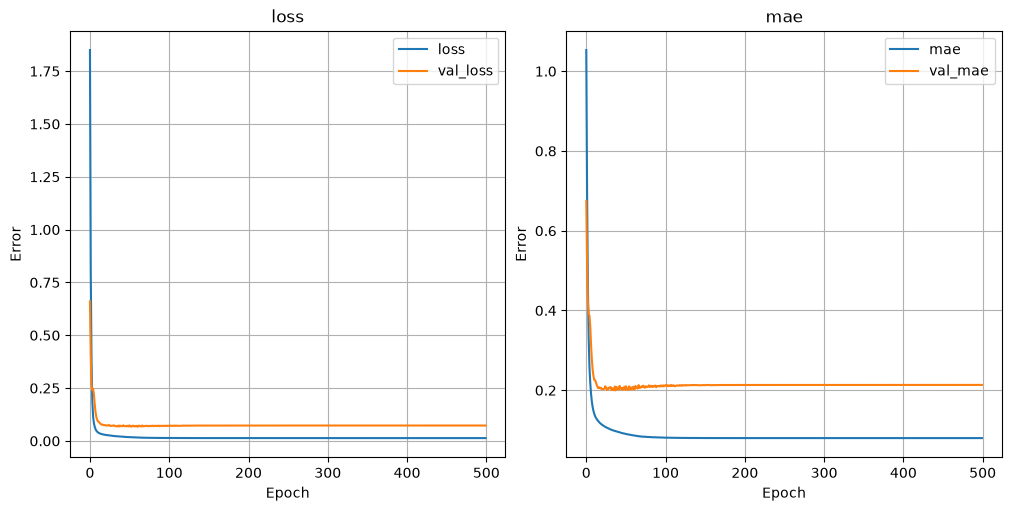

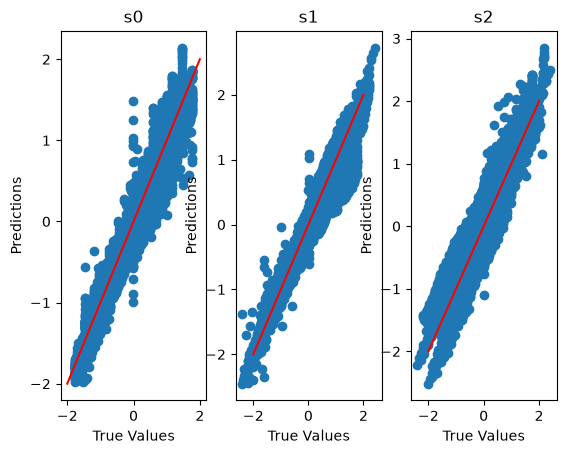

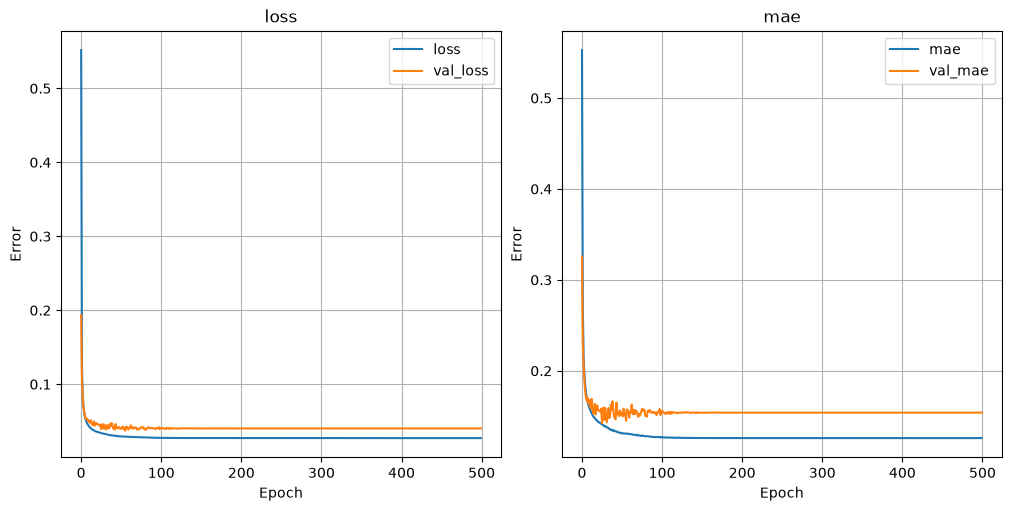

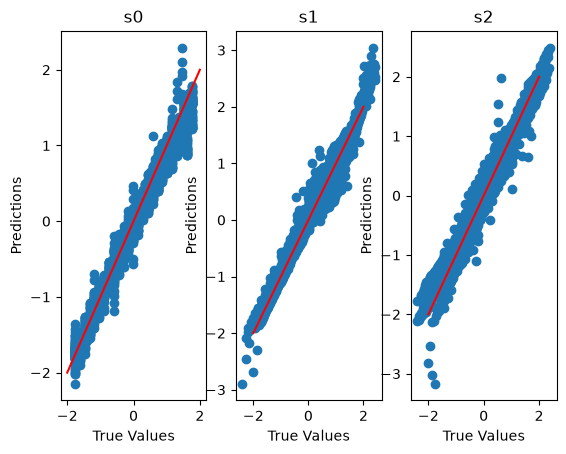

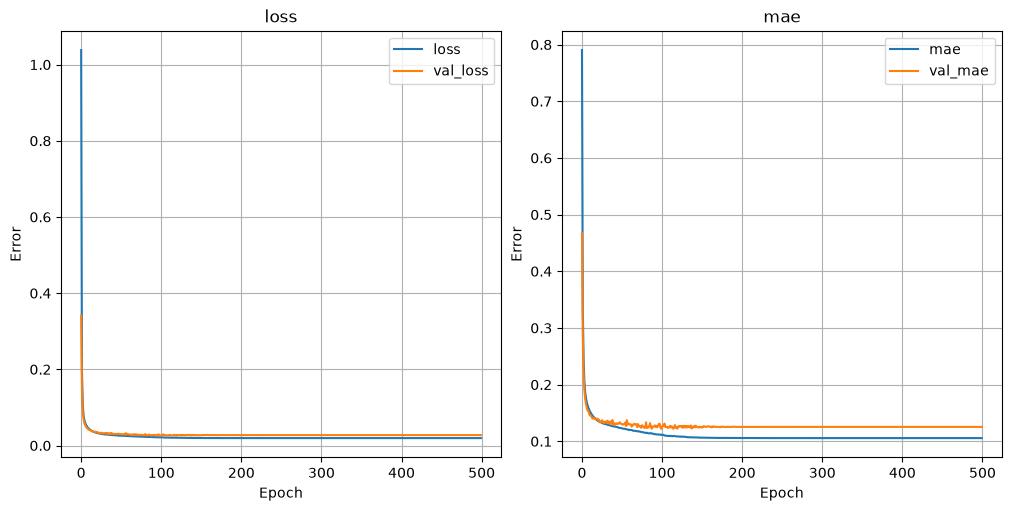

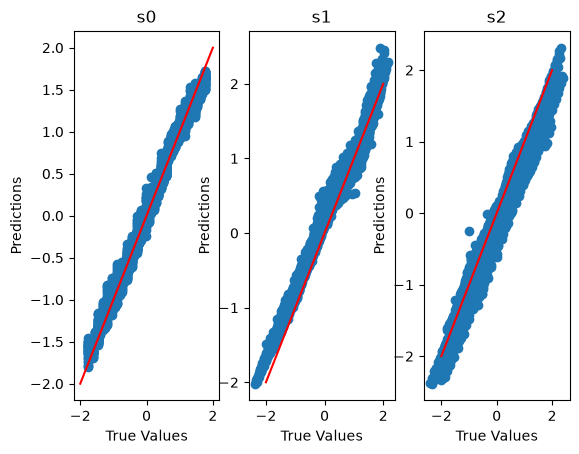

In [11]:
scalerX = StandardScaler().fit(inputs)
scalerY = StandardScaler().fit(outputs)

X = scalerX.transform(inputs)
y = scalerY.transform(outputs)

scores = []



tscv = TimeSeriesSplit(n_splits=3)
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X.shape[1], y.shape[1])
    # model.summary() #investigate

    history = train_model(model, X_train, y_train, verbose=0, epochs=500)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)
    plot_motors(y_test, y_pred, [-2,2])

print("MSE scores for each fold:", scores)